# In-class Competition Tutorial
This NOTEBOOK will provide an introduction to the process of creating forecast results and the basic methodology.

First, let's review the task we will be performing (see README.ipynb for details).

**Objective**: To predict the probability of default based on customer data.

**Evaluation metric**: ROC-AUC (Area Under the Receiver Operating Characteristic Curve)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Contents
- [1.Setup](#scrollTo=a5KcDAE8CnmB)
- [2.Loading the Data](#scrollTo=tp0cW0CD11Hi&line=1&uniqifier=1)
- [3.Visualizing and Understanding the Data](#scrollTo=3NuP1zcmCnmF&line=1&uniqifier=1)
- [4.Preprocessing and Feature Creation](#scrollTo=rsPYkguwCnmO&line=1&uniqifier=1)
- [5.Building the Machine Learning Model](#scrollTo=FoKdK60PCnmP&line=1&uniqifier=1)
- [6.Creating prediction results](#scrollTo=tn_kdvWYCnmQ&line=2&uniqifier=1)

## 1.Setup

### 1.1 Import Libraries
Let's load basic libraries.
Other required libraries will be loaded when we explain them.
- numpy: Library for efficient numerical computation
- pandas: Library useful for data analysis
- matplotlib: Graph drawing library
- seaborn: Graph drawing library as well

In [ ]:
# Importing libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

### 1.2 Connect with Google Drive
To load the data, we first need to connect this Colab notebook with Google Drive.

In [ ]:
# If you work with Google Colaboratory, please run this as well.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Next, we need to navigate to where the `competition` folder is located

**IMPORTANT**:<br>
Change the path in the `%cd` command below to match the folder where this notebook is saved on Google Drive by **replacing "WhereThisNotebookIsLocated" with your actual folder path**.

Examples:
- You uploaded `competition` folder directly under MyDrive (the default folder when you open Google Drive)
    - Change to "/<wbr>content/drive/MyDrive/competition"
- You uploaded `competition` folder inside a folder named `00_GCIGlobal` under MyDrive
    - Change to "/<wbr>content/drive/MyDrive/00_GCIGlobal/competition"

You can easily locate your notebook's directory by:
1. Open the Files panel on the left side of Colab
2. Navigate through the "drive" and "MyDrive" folders until you find your notebook's folders
3. Click the more actions icon (three vertical dots, $\vdots$) next to the folder name
4. Select the option "Copy path"

In [ ]:
# Specify the directory where this notebook is located after %cd.
%cd "/content/drive/MyDrive/Competition"

/content/drive/MyDrive/Competition


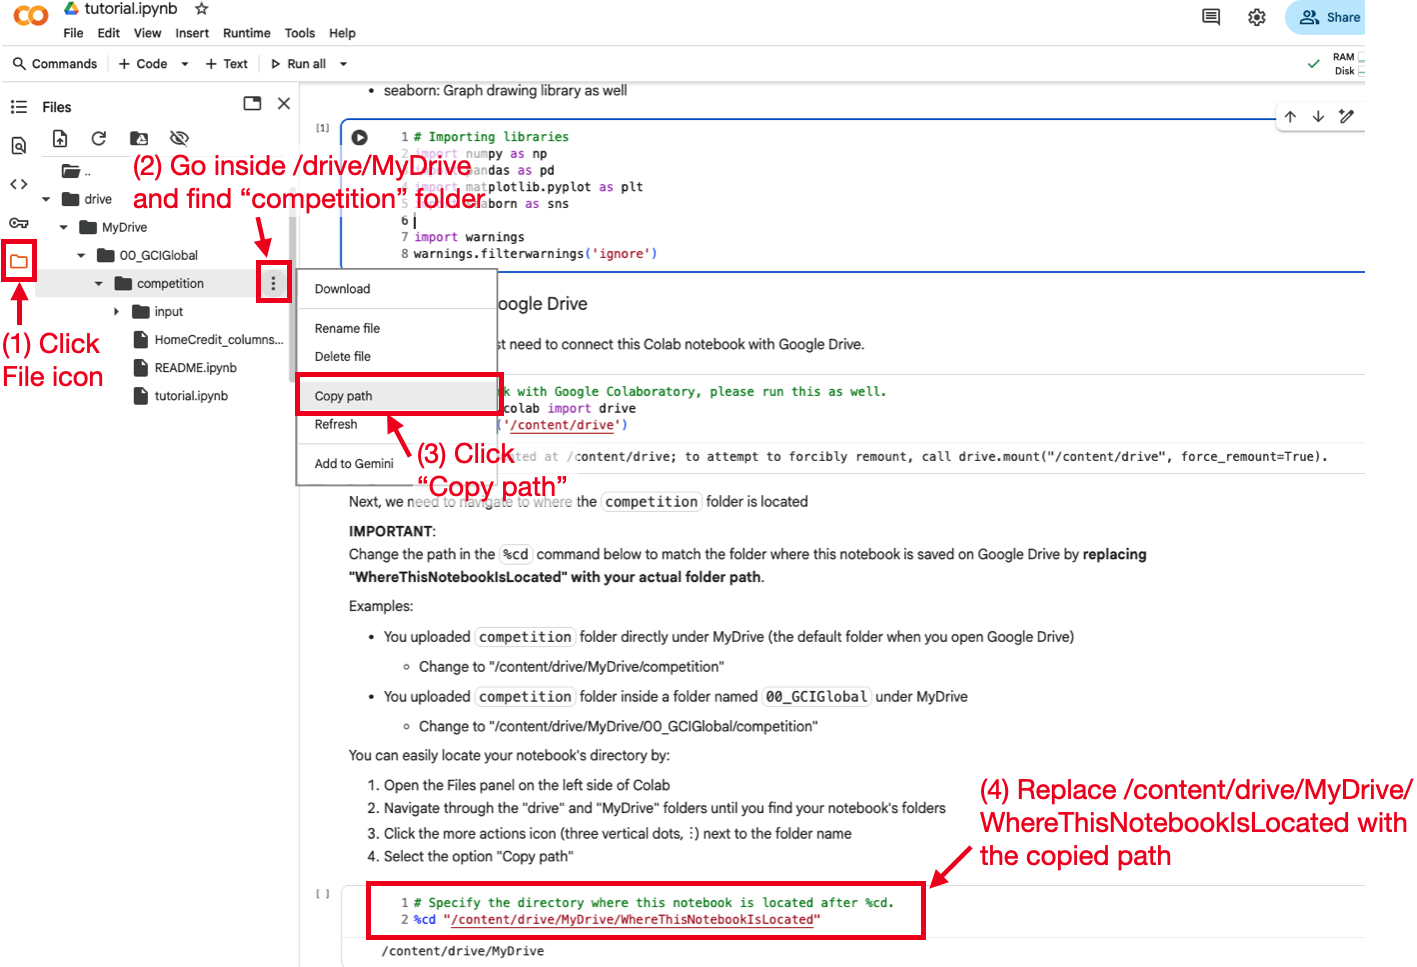

Run the cell below to check if the path is correctly set.

In [ ]:
import os
from pathlib import Path

# Automatically get the current working directory
current_dir = Path(os.getcwd())

# Define file paths using pathlib
train_file = current_dir / "input" / "train.csv"
test_file = current_dir / "input" / "test.csv"
sample_sub_file = current_dir / "input" / "sample_submission.csv"

# Check if path exists
if train_file.exists() and test_file.exists() and sample_sub_file.exists():
    print("All files exist and path is correctly set.")
else:
    print("Some files are missing or path is not correctly set.")

All files exist and path is correctly set.


## 2.Loading the Data

### 2.1 Data Overview
Run the cell to load the dataset as `pd.DataFrame`.

**IMPORTANT:**<br>
**When you make modifications to preprocessing or model training, always make sure to run all cells from this cell.**

In [70]:
train = pd.read_csv(train_file)
test = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)

Before conducting a full-scale analysis, we will first review a brief overview of the data.

In [71]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 34)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
0,0,Cash loans,F,0,112500.0,755190.0,36328.5,675000.0,Working,Higher education,Married,House / apartment,0.010032,-9233,-878,-333.0,-522,NaN,1,1,1,Core staff,2.0,2,School,NaN,0.372591,NaN,-292.0,NaN,NaN,NaN,NaN,0
1,1,Cash loans,F,0,225000.0,585000.0,16893.0,585000.0,Pensioner,Secondary / secondary special,Married,House / apartment,0.008019,-20148,365243,-4469.0,-3436,NaN,1,0,0,Other,2.0,2,XNA,NaN,0.449567,0.553165,-617.0,0.0,0.0,0.0,1.0,0
2,2,Cash loans,F,0,54000.0,334152.0,18256.5,270000.0,State servant,Secondary / secondary special,Married,House / apartment,0.004960,-18496,-523,-3640.0,-2050,NaN,1,1,1,Core staff,2.0,2,Postal,NaN,0.569503,NaN,-542.0,NaN,NaN,NaN,NaN,0


In [72]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 33)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,171202,Cash loans,F,1,144000.0,961146.0,28233.0,688500.0,Working,Higher education,Married,House / apartment,0.025164,-12108,-2372,-2446.0,-3022,NaN,1,1,0,Medicine staff,3.0,2,Kindergarten,NaN,0.720416,NaN,-1.0,NaN,NaN,NaN,NaN
1,171203,Cash loans,F,0,103500.0,296280.0,16069.5,225000.0,Working,Secondary / secondary special,Married,House / apartment,0.007020,-17907,-1712,-10450.0,-253,NaN,1,1,1,Cleaning staff,2.0,2,School,NaN,0.287306,NaN,-212.0,NaN,NaN,NaN,NaN
2,171204,Cash loans,F,1,180000.0,183694.5,11236.5,139500.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,0.006852,-15221,-553,-1056.0,-4495,NaN,1,1,0,Other,2.0,3,Trade: type 7,NaN,0.352456,0.389339,-428.0,0.0,1.0,1.0,1.0


Excluding the `TARGET` column in train data and the `SK_ID_CURR` which represents ID number, you can see that there are 32 types of features.

### 2.2 Selecting Features

It is often difficult to perform data analysis and preprocessing on all features from the beginning. Instead, an easier way to get started is to start with a small number of features and then add features one by one.

This notebook will focus on 5 features. For the remaining 25 types of features, please refer to the lecture materials, the methods introduced in this notebook, etc., and perform the analysis on your own.

Feel free to also ask questions in lectures, office hours, or in the Slack community!

ADDING THREE SELF-BUILD RATIOS FOR DEEPER UNDERSTANDING

In [73]:
use_features = [
    #Baseline features
     "NAME_CONTRACT_TYPE",
    "AMT_INCOME_TOTAL",
    "EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3",
    "DAYS_BIRTH", "DAYS_EMPLOYED",
    "ORGANIZATION_TYPE", "OWN_CAR_AGE",
    "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE",
    "AMT_REQ_CREDIT_BUREAU_HOUR",
    "AMT_REQ_CREDIT_BUREAU_MON",
    "AMT_REQ_CREDIT_BUREAU_QRT",
    "AMT_REQ_CREDIT_BUREAU_YEAR",
    "CODE_GENDER", "REGION_RATING_CLIENT",
    "DAYS_LAST_PHONE_CHANGE", "CNT_FAM_MEMBERS",
    "CNT_CHILDREN", "NAME_INCOME_TYPE",
    "NAME_HOUSING_TYPE", "REGION_POPULATION_RELATIVE",
    "DAYS_REGISTRATION", "DAYS_ID_PUBLISH",

    #Demographic and socioeconomic features
    "NAME_FAMILY_STATUS",
    "OCCUPATION_TYPE",
    "FLAG_EMP_PHONE",
    "FLAG_WORK_PHONE",
    "FLAG_MOBIL",

    #Basic financial ratios
    "CREDIT_INCOME_RATIO",
    "ANNUITY_INCOME_RATIO",
    "CREDIT_GOODS_RATIO",
    "GOODS_INCOME_RATIO",
    "ANNUITY_CREDIT_RATIO",
    "INCOME_PER_PERSON",
    "CREDIT_PER_PERSON",
    "CREDIT_MINUS_GOODS",
    "AGE_YEARS",
    "INCOME_TO_AGE_RATIO",

    #Employment and external-score engineering
     "EMPLOYED_TO_AGE_RATIO",
    "EXT_SOURCES_MEAN",
    "EXT_SOURCES_PROD",
    "EXT_SOURCES_STD",

    #Additional affordability features

    "INCOME_AFTER_ANNUITY",
    "ESTIMATED_REPAYMENT_DURATION",
    "CREDIT_TO_FAMILY_INCOME_CAPACITY",
    "GOODS_FINANCING_GAP_RATIO"

]

In [74]:
for df in [train, test]:
    # 1. Employment length relative to age (Fraction of life spent working)
    df['EMPLOYED_TO_AGE_RATIO'] = df['DAYS_EMPLOYED'] / df['DAYS_BIRTH']

    # 2. Combined External Scores (EXT_SOURCE columns are massive predictors in Home Credit)
    df['EXT_SOURCES_MEAN'] = df[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].mean(axis=1)
    df['EXT_SOURCES_PROD'] = df['EXT_SOURCE_1'] * df['EXT_SOURCE_2'] * df['EXT_SOURCE_3']
    df['EXT_SOURCES_STD'] = df[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].std(axis=1)

    # 3. Debt burden score
    df['DEBT_BURDEN_SCORE'] = df['AMT_ANNUITY'] / (df['AMT_CREDIT'] + 1)

    # 4. Goods-to-Income: How expensive are the goods relative to annual income?
    df['GOODS_INCOME_RATIO'] = df['AMT_GOODS_PRICE'] / (df['AMT_INCOME_TOTAL'] + 1)

    # 5. Annuity-to-Credit: Repayment burden relative to total loan amount
    df['ANNUITY_CREDIT_RATIO'] = df['AMT_ANNUITY'] / (df['AMT_CREDIT'] + 1)

    # 6. Income-per-Person / Family Burden: Income divided by family members
    df['INCOME_PER_PERSON'] = df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS'].replace(0, 1)

    # 7. Credit-per-Person: Credit size per family member
    df['CREDIT_PER_PERSON'] = df['AMT_CREDIT'] / df['CNT_FAM_MEMBERS'].replace(0, 1)

    # 8. Credit Minus Goods: Measures debt overhang/extra cash requested on top of goods
    df['CREDIT_MINUS_GOODS'] = df['AMT_CREDIT'] - df['AMT_GOODS_PRICE']

    # 9. Age in Years (from negative days)
    df['AGE_YEARS'] = -df['DAYS_BIRTH'] / 365.25

    # 10. Income-to-Age Ratio: Earning capacity relative to age
    df['INCOME_TO_AGE_RATIO'] = df['AMT_INCOME_TOTAL'] / df['AGE_YEARS']

    # 11. Credit-to-Income Ratio (How large is the loan relative to earnings?)
    df['CREDIT_INCOME_RATIO'] = df['AMT_CREDIT'] / df['AMT_INCOME_TOTAL']

    # 12. Annuity-to-Income Ratio (How heavy is the monthly repayment burden?)
    df['ANNUITY_INCOME_RATIO'] = df['AMT_ANNUITY'] / df['AMT_INCOME_TOTAL']

    # 13. Credit-to-Goods Price Ratio (Loan amount versus the actual item value)
    df['CREDIT_GOODS_RATIO'] = df['AMT_CREDIT'] / df['AMT_GOODS_PRICE']

    # 14. Income remaining after annualized repayments
    df['INCOME_AFTER_ANNUITY'] = df['AMT_INCOME_TOTAL'] - (12 * df['AMT_ANNUITY'])

    # 15. Estimated loan repayment duration
    df['ESTIMATED_REPAYMENT_DURATION'] = df['AMT_CREDIT'] / (df['AMT_ANNUITY'] + 1)

    # 16. Credit relative to family income capacity
    df['CREDIT_TO_FAMILY_INCOME_CAPACITY'] = df['AMT_CREDIT'] / (df['AMT_INCOME_TOTAL'] / df['CNT_FAM_MEMBERS'].replace(0, 1) + 1)

    # 17. Goods financing gap ratio
    df['GOODS_FINANCING_GAP_RATIO'] = (df['AMT_CREDIT'] - df['AMT_GOODS_PRICE']) / (df['AMT_GOODS_PRICE'] + 1)



In [75]:
target = train["TARGET"].values
train = train[use_features]
train["TARGET"] = target
test = test[use_features]

Let's check the data once again.

In [76]:
# Check test data
print(f"test shape: {test.shape}")
test.head(3)

test shape: (61500, 49)


,NAME_CONTRACT_TYPE,AMT_INCOME_TOTAL,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_BIRTH,DAYS_EMPLOYED,ORGANIZATION_TYPE,OWN_CAR_AGE,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,CODE_GENDER,REGION_RATING_CLIENT,DAYS_LAST_PHONE_CHANGE,CNT_FAM_MEMBERS,CNT_CHILDREN,NAME_INCOME_TYPE,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_REGISTRATION,DAYS_ID_PUBLISH,NAME_FAMILY_STATUS,OCCUPATION_TYPE,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_MOBIL,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_GOODS_RATIO,GOODS_INCOME_RATIO,ANNUITY_CREDIT_RATIO,INCOME_PER_PERSON,CREDIT_PER_PERSON,CREDIT_MINUS_GOODS,AGE_YEARS,INCOME_TO_AGE_RATIO,EMPLOYED_TO_AGE_RATIO,EXT_SOURCES_MEAN,EXT_SOURCES_PROD,EXT_SOURCES_STD,INCOME_AFTER_ANNUITY,ESTIMATED_REPAYMENT_DURATION,CREDIT_TO_FAMILY_INCOME_CAPACITY,GOODS_FINANCING_GAP_RATIO
0,Cash loans,144000.0,NaN,0.720416,NaN,-12108,-2372,Kindergarten,NaN,961146.0,28233.0,688500.0,NaN,NaN,NaN,NaN,F,2,-1.0,3.0,1,Working,House / apartment,0.025164,-2446.0,-3022,Married,Medicine staff,1,0,1,6.674625,0.196063,1.396000,4.781217,0.029374,48000.0,320382.00,272646.0,33.149897,4343.904856,0.195904,0.720416,NaN,NaN,-194796.0,34.042148,20.023458,0.395999
1,Cash loans,103500.0,NaN,0.287306,NaN,-17907,-1712,School,NaN,296280.0,16069.5,225000.0,NaN,NaN,NaN,NaN,F,2,-212.0,2.0,0,Working,House / apartment,0.007020,-10450.0,-253,Married,Cleaning staff,1,1,1,2.862609,0.155261,1.316800,2.173892,0.054237,51750.0,148140.00,71280.0,49.026694,2111.094823,0.095605,0.287306,NaN,NaN,-89334.0,18.436265,5.725107,0.316799
2,Cash loans,180000.0,NaN,0.352456,0.389339,-15221,-553,Trade: type 7,NaN,183694.5,11236.5,139500.0,0.0,1.0,1.0,1.0,F,3,-428.0,2.0,1,Commercial associate,House / apartment,0.006852,-1056.0,-4495,Single / not married,Other,1,0,1,1.020525,0.062425,1.316806,0.774996,0.061169,90000.0,91847.25,44194.5,41.672827,4319.361409,0.036331,0.370897,NaN,0.02608,45162.0,16.346563,2.041027,0.316804


In [77]:
# List of columns to convert to integer
cols_to_convert = ["AMT_INCOME_TOTAL","OWN_CAR_AGE","AMT_CREDIT","AMT_GOODS_PRICE","DAYS_LAST_PHONE_CHANGE","CNT_FAM_MEMBERS","DAYS_REGISTRATION","INCOME_PER_PERSON","CREDIT_PER_PERSON","CREDIT_MINUS_GOODS","INCOME_AFTER_ANNUITY","AGE_YEARS"]

for col in cols_to_convert:
    if col in train.columns:
        # Fill any NaN values if present before converting (e.g., with 0 or a placeholder)
        train[col] = train[col].fillna(0).astype(int)

    if col in test.columns:
        test[col] = test[col].fillna(0).astype(int)



In [78]:
# Explicitly list the columns you want to convert to object data type
cols_to_convert_to_object = ["REGION_RATING_CLIENT", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE","FLAG_MOBIL","AMT_REQ_CREDIT_BUREAU_HOUR","AMT_REQ_CREDIT_BUREAU_QRT","AMT_REQ_CREDIT_BUREAU_YEAR","AMT_REQ_CREDIT_BUREAU_MON"]

for col in cols_to_convert_to_object:
    if col in train.columns:
        train[col] = train[col].astype(object)
    if col in test.columns:
        test[col] = test[col].astype(object)

In [79]:
# Separate columns by their data types
numeric_cols = train.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()
object_cols = train.select_dtypes(include=["object", "category"]).columns.tolist()

# Ensure 'TARGET' stays at the very end if it's present in train
if "TARGET" in numeric_cols:
    numeric_cols.remove("TARGET")
    target_in_numeric = True
else:
    target_in_numeric = False

# Reorder: Numeric columns first, then object columns, and TARGET at the tail
new_column_order = numeric_cols + object_cols
if target_in_numeric or "TARGET" in train.columns:
    if "TARGET" not in new_column_order:
        new_column_order.append("TARGET")

# Apply the new ordering to both train and test datasets
train = train[new_column_order]

# For test set (which doesn't have the TARGET column)
test_cols = [col for col in new_column_order if col != "TARGET"]
test = test[test_cols]

# Verify the new structure
print(f"Total columns reordered: {len(train.columns)}")
train.info()

Total columns reordered: 50
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 50 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   AMT_INCOME_TOTAL                  171202 non-null  int64  
 1   EXT_SOURCE_1                      52274 non-null   float64
 2   EXT_SOURCE_2                      170833 non-null  float64
 3   EXT_SOURCE_3                      116616 non-null  float64
 4   DAYS_BIRTH                        171202 non-null  int64  
 5   DAYS_EMPLOYED                     171202 non-null  int64  
 6   OWN_CAR_AGE                       171202 non-null  int64  
 7   AMT_CREDIT                        171202 non-null  int64  
 8   AMT_ANNUITY                       171202 non-null  float64
 9   AMT_GOODS_PRICE                   171202 non-null  int64  
 10  DAYS_LAST_PHONE_CHANGE            171202 non-null  int64  
 11  CNT_FAM_MEMBERS         

In [80]:
# Check train data
print(f"train shape: {train.shape}")
train.head(3)

train shape: (171202, 50)


,AMT_INCOME_TOTAL,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_BIRTH,DAYS_EMPLOYED,OWN_CAR_AGE,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_LAST_PHONE_CHANGE,CNT_FAM_MEMBERS,CNT_CHILDREN,REGION_POPULATION_RELATIVE,DAYS_REGISTRATION,DAYS_ID_PUBLISH,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_GOODS_RATIO,GOODS_INCOME_RATIO,ANNUITY_CREDIT_RATIO,INCOME_PER_PERSON,CREDIT_PER_PERSON,CREDIT_MINUS_GOODS,AGE_YEARS,INCOME_TO_AGE_RATIO,EMPLOYED_TO_AGE_RATIO,EXT_SOURCES_MEAN,EXT_SOURCES_PROD,EXT_SOURCES_STD,INCOME_AFTER_ANNUITY,ESTIMATED_REPAYMENT_DURATION,CREDIT_TO_FAMILY_INCOME_CAPACITY,GOODS_FINANCING_GAP_RATIO,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,CODE_GENDER,REGION_RATING_CLIENT,NAME_INCOME_TYPE,NAME_HOUSING_TYPE,NAME_FAMILY_STATUS,OCCUPATION_TYPE,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_MOBIL,TARGET
0,112500,NaN,0.372591,NaN,-9233,-878,0,755190,36328.5,675000,-292,2,0,0.010032,-333,-522,6.7128,0.322920,1.1188,5.999947,0.048105,56250,377595,80190,25,4450.408860,0.095094,0.372591,NaN,NaN,-323442,20.787239,13.425361,0.118800,Cash loans,School,NaN,NaN,NaN,NaN,F,2,Working,House / apartment,Married,Core staff,1,1,1,0
1,225000,NaN,0.449567,0.553165,-20148,365243,0,585000,16893.0,585000,-617,2,0,0.008019,-4469,-3436,2.6000,0.075080,1.0000,2.599988,0.028877,112500,292500,0,55,4078.878797,-18.128003,0.501366,NaN,0.073255,22284,34.627678,5.199954,0.000000,Cash loans,XNA,0.0,0.0,0.0,1.0,F,2,Pensioner,House / apartment,Married,Other,0,0,1,0
2,54000,NaN,0.569503,NaN,-18496,-523,0,334152,18256.5,270000,-542,2,0,0.004960,-3640,-2050,6.1880,0.338083,1.2376,4.999907,0.054635,27000,167076,64152,50,1066.365701,0.028276,0.569503,NaN,NaN,-165078,18.302177,12.375542,0.237599,Cash loans,Postal,NaN,NaN,NaN,NaN,F,2,State servant,House / apartment,Married,Core staff,1,1,1,0


In [81]:
# Print unique values for all object (categorical) columns
for col in train.columns:
    if train[col].dtype == "object":
        print(f"Column: {col}")
        print(df[col].unique())
        print("-" * 50)

Column: NAME_CONTRACT_TYPE
['Cash loans' 'Revolving loans']
--------------------------------------------------
Column: ORGANIZATION_TYPE
['Kindergarten' 'School' 'Trade: type 7' 'Business Entity Type 3'
 'Self-employed' 'Security' 'Medicine' 'Electricity' 'XNA' 'Other'
 'Government' 'Military' 'Trade: type 3' 'Transport: type 3'
 'Security Ministries' 'Police' 'Construction' 'Transport: type 2'
 'Business Entity Type 2' 'Transport: type 4' 'Trade: type 6'
 'Business Entity Type 1' 'Agriculture' 'Restaurant' 'Industry: type 4'
 'Mobile' 'Trade: type 2' 'Industry: type 5' 'Cleaning' 'Industry: type 1'
 'Postal' 'Emergency' 'Bank' 'Housing' 'Industry: type 11'
 'Industry: type 3' 'Services' 'Industry: type 7' 'Legal Services'
 'Industry: type 9' 'Advertising' 'Culture' 'University'
 'Industry: type 2' 'Hotel' 'Insurance' 'Telecom' 'Realtor'
 'Industry: type 6' 'Trade: type 1' 'Trade: type 4' 'Transport: type 1'
 'Industry: type 13' 'Industry: type 10' 'Industry: type 12'
 'Trade: type 5' 

## 3.Visualizing and Understanding the Data

### 3.1 Checking missing values
In this section, we check for missing values.
This is important as **most machine learning models cannot be trained on data with missing values**. If there are missing values, they need to be filled with some value.

In [69]:
# Check missing values of test data
test.isnull().sum()

,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_1,42912
EXT_SOURCE_2,130
EXT_SOURCE_3,19690
DAYS_BIRTH,0
DAYS_EMPLOYED,0
OWN_CAR_AGE,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0


We found that there are missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`. We will deal with these missing values later. Of course, there is a possibility that there are missing values for other features that we are not covering here, so please check them by yourself.

**Findings**:<br>
* Need to deal with missing values in `EXT_SOURCE_2` and `OWN_CAR_AGE`

### 3.2 Visualization and analysis of each feature
In this section, we visualize each feature and analyze to see what kind of characteristics it has.

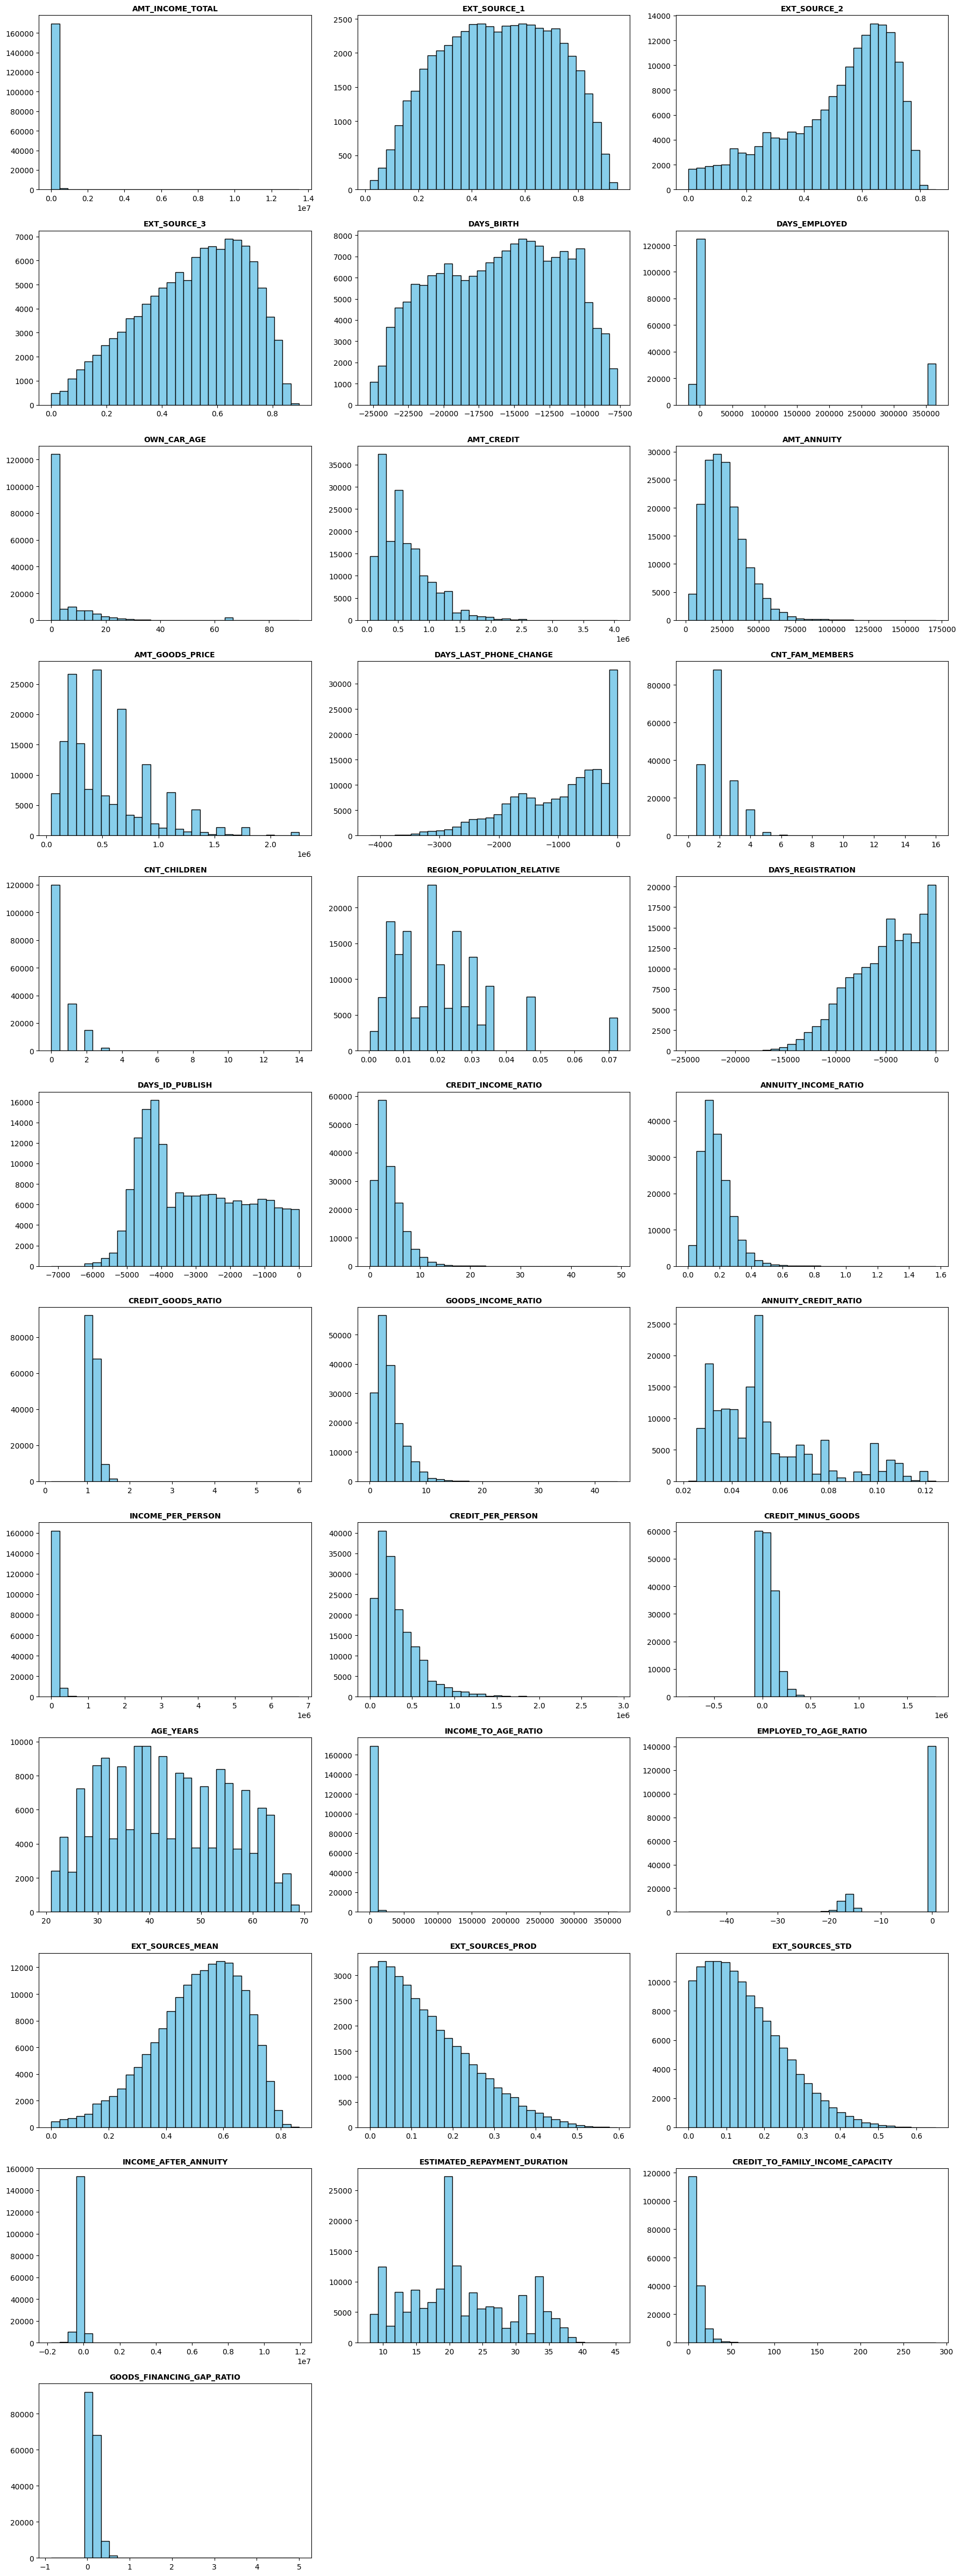

In [82]:
import matplotlib.pyplot as plt

# Select all numeric columns (both integers and floats)
numeric_cols = train.select_dtypes(
    include=["int64", "int32", "float64", "float32"]
).columns.tolist()

# Remove TARGET, IDs, or non-feature columns if they exist in the list
exclude_cols = ["TARGET", "SK_ID_CURR"]
numeric_cols = [col for col in numeric_cols if col not in exclude_cols]

# Set up the plotting grid (3 columns wide)
n_cols = 3
n_rows = (len(numeric_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

# Plot histograms for each numeric/engineered column
for i, col in enumerate(numeric_cols):
    train[col].dropna().hist(
        ax=axes[i], bins=30, color="skyblue", edgecolor="black"
    )
    axes[i].set_title(col, fontsize=10, fontweight="bold")
    axes[i].grid(False)

# Hide any unused empty subplots in the grid
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### TARGET column

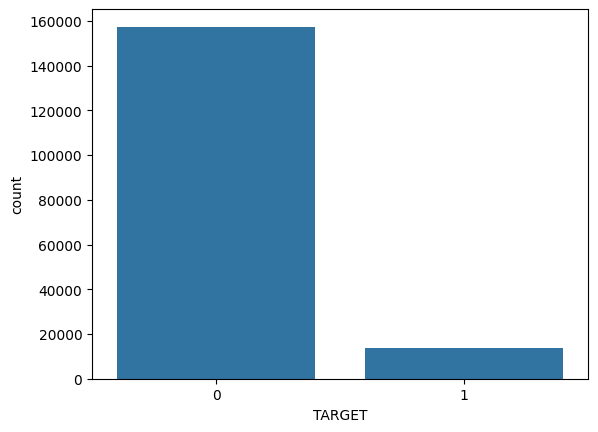

In [64]:
# The distribution of the target (default or not)
sns.countplot(data=train, x="TARGET")
plt.show()

We can see that the **distribution of the objective variable is highly skewed**. Data in which the distribution of the objective variable is highly skewed in this way is called **unbalanced data**.

When dealing with unbalanced data, we need to be particularly careful in selecting evaluation metrics. For example, if you choose accuracy, you will find that simply predicting all zeros will result in a high accuracy. **Choosing such an inappropriate metric can cause the machine learning model to fail to predict well on new data**.

Another approach to dealing with unbalanced data is to try to balance the distribution of the target variable. The method of reducing the data of the larger target variable is called undersampling, while the method of increasing the data of the smaller objective variable is called oversampling.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable

#### NAME_CONTRACT_TYPE column

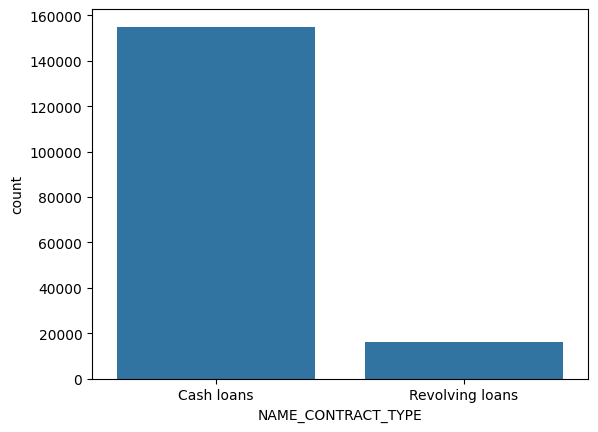

In [65]:
# The distribution of NAME_CONTRACT_TYPE
sns.countplot(data=train, x="NAME_CONTRACT_TYPE")
plt.show()

There are two variables in `NAME_CONTRACT_TYPE`, Cash loans and Revolving loans, but they are not evenly distributed. Also, since the machine learning model can only handle data of numeric type, it is necessary to convert the data from string type to numeric type.

**Findings**:<br>
* (May) need to think about methods to mitigate the skewedness of the target variable
* Need to convert the data from string type to numeric type

#### ORGANIZATION_TYPE column

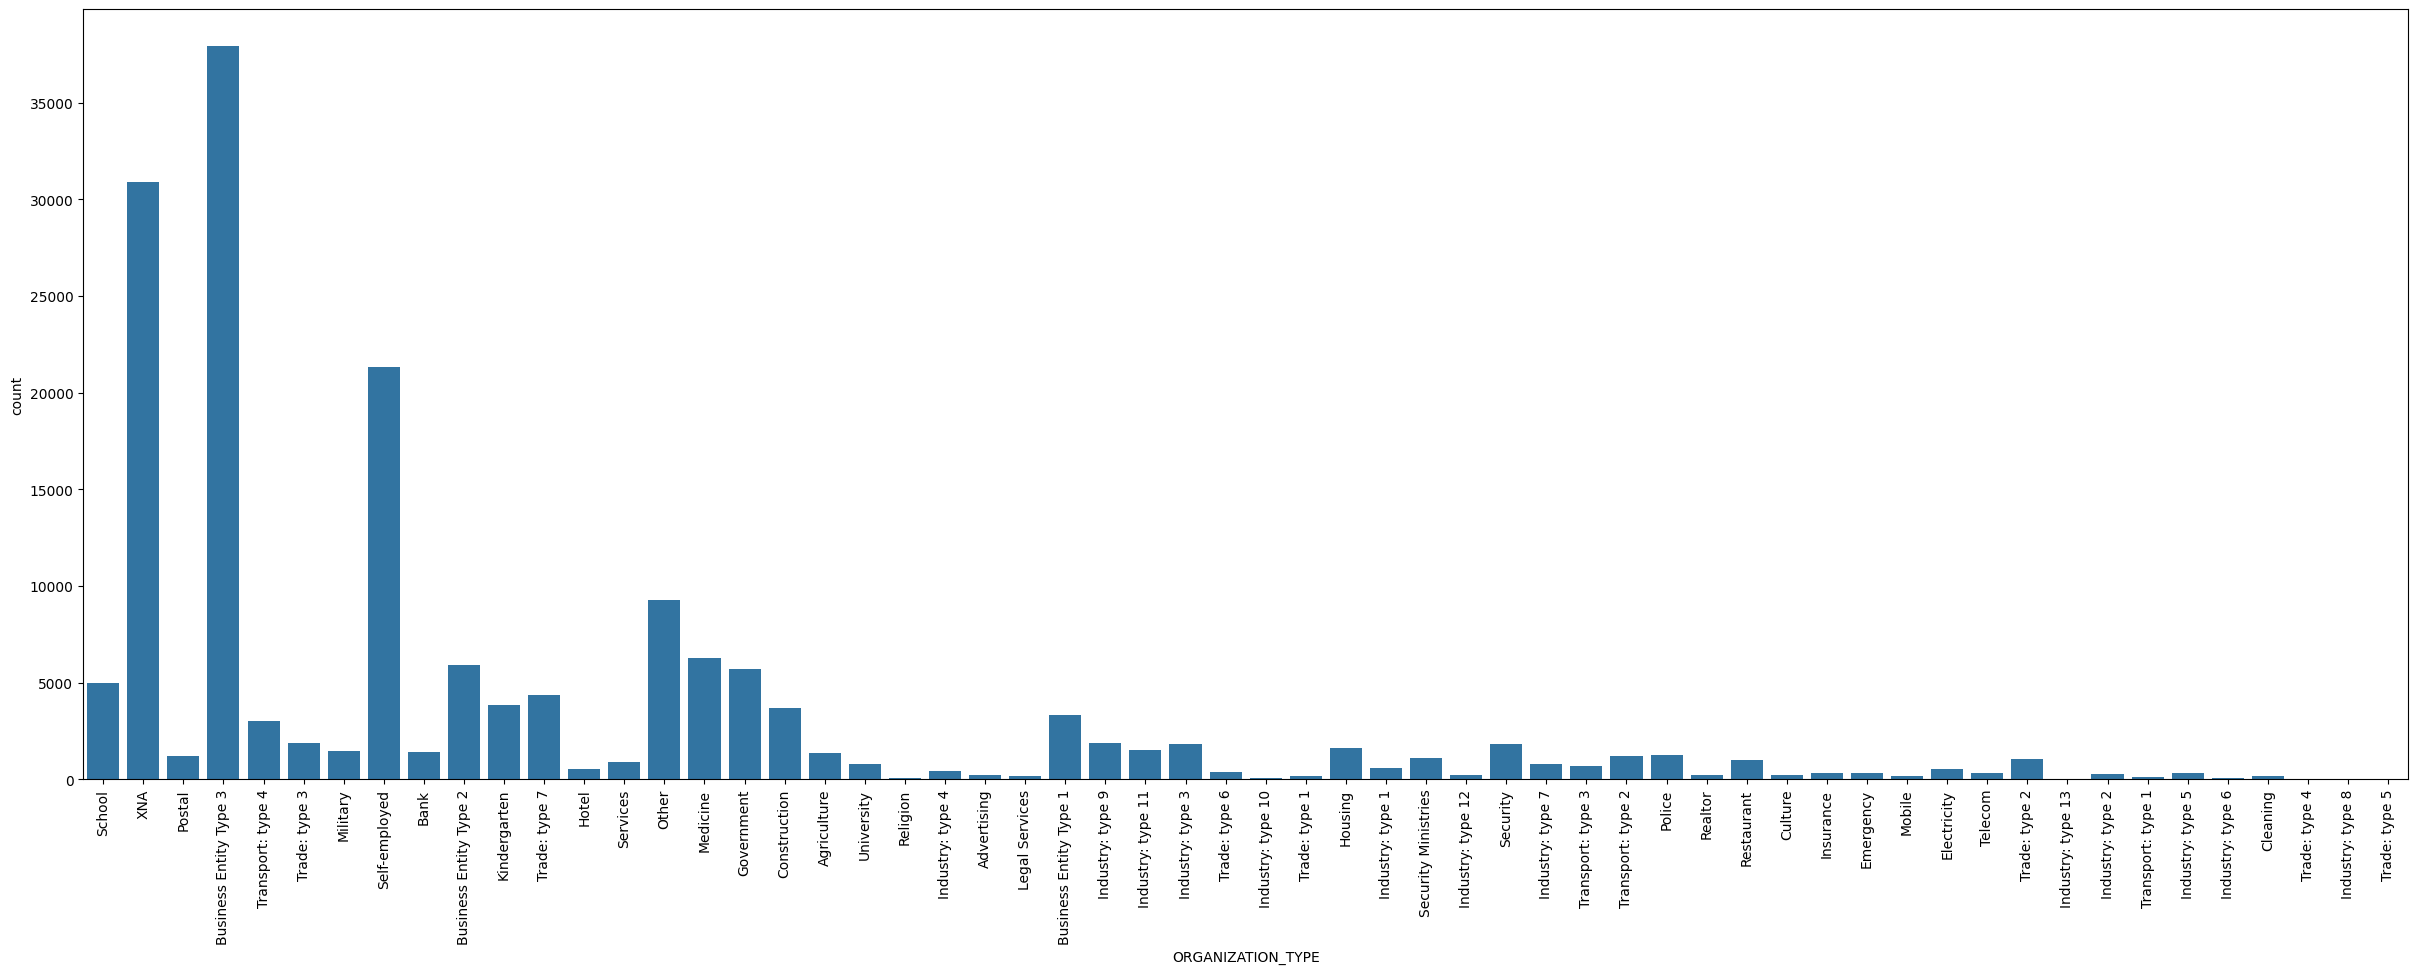

In [ ]:
# The distribution of ORGANIZATION_TYPE
plt.figure(figsize=(30, 10))
sns.countplot(data=train, x="ORGANIZATION_TYPE")
plt.tick_params(axis="x", rotation=90)
plt.show()

There are many different `ORGANIZATION_TYPE`s, and you can also see that there is an ununiformity in the number of data. This is also a string type feature, so it needs to be converted to a numeric type. Also, the second variable from the left is "XNA", which we can infer from its name to be a missing value.


**Findings**:<br>
* Treat "XNA" as missing values
* Need to convert the data from string type to numeric type

#### EXT_SOURCE_2 column

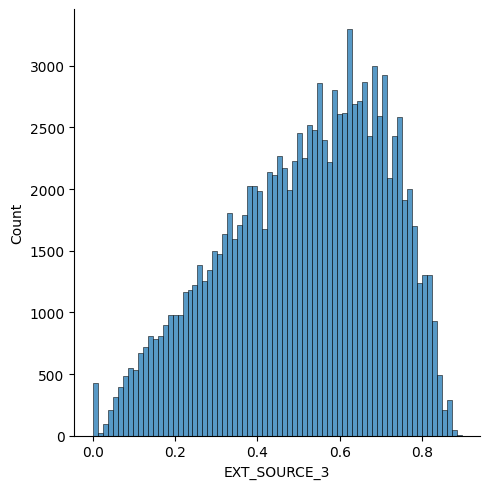

In [ ]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_3")
plt.show()

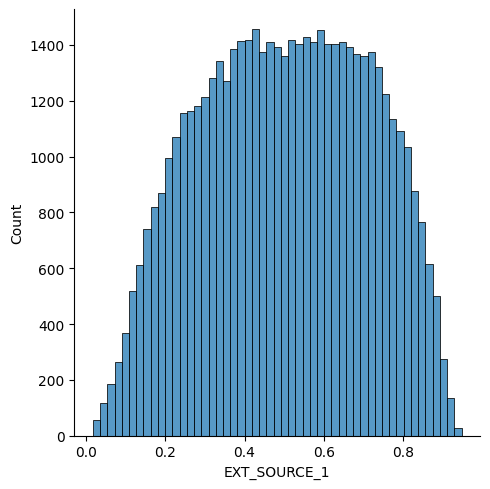

In [ ]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_1")
plt.show()

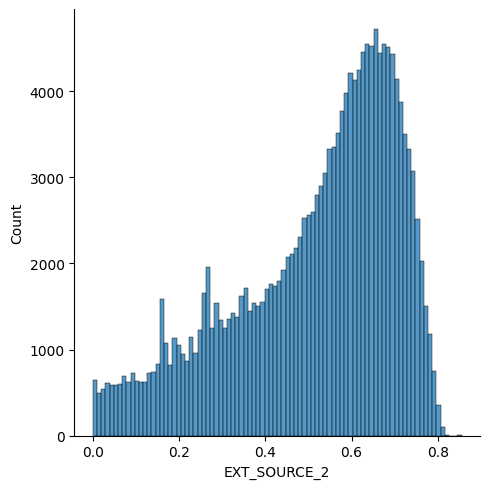

In [ ]:
# The distribution of EXT_SOURCE_2
sns.displot(data=train, x="EXT_SOURCE_2")
plt.show()

We can see that EXT_SOURCE_2 is normalized between 0 and 1. It seems we can handle this feature as it is.

**Findings**:<br>
* No additional preprocessing is needed

**AMT_CREDIT**

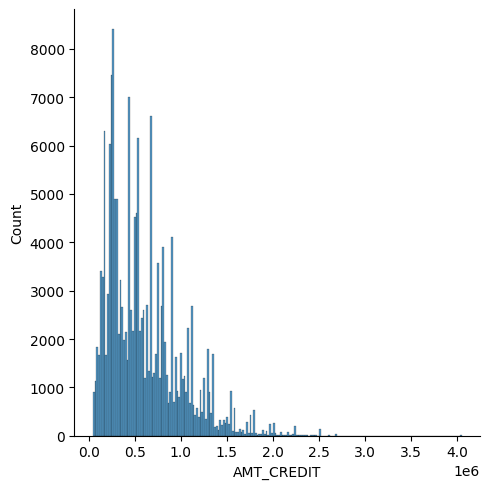

In [ ]:
# The distribution of AMT_CREDIT
sns.displot(data=train, x="AMT_CREDIT")
plt.show()

"AMT_ANNUITY"

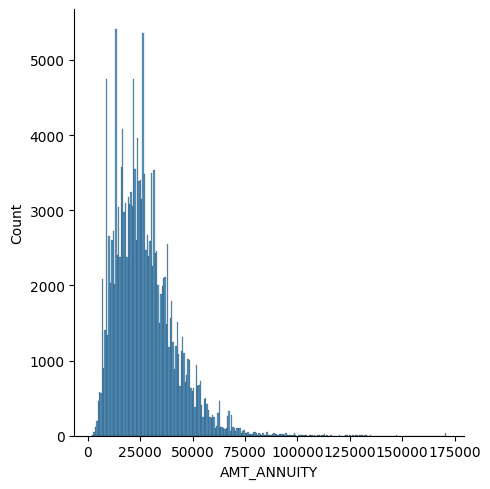

In [ ]:
# The distribution of AMT_ANNUITY
sns.displot(data=train, x="AMT_ANNUITY")
plt.show()

**AMT_GOODS_PRICE**

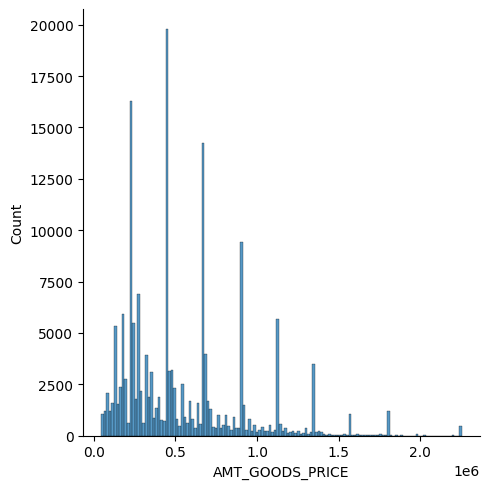

In [ ]:
# The distribution of AMT_GOODS_PRICE
sns.displot(data=train, x="AMT_GOODS_PRICE")
plt.show()

#### AMT_INCOME_TOTAL column

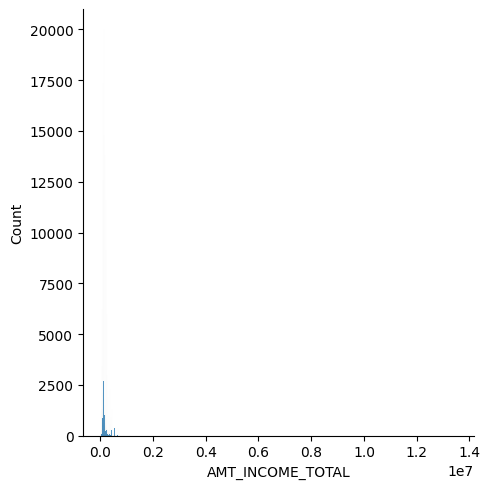

In [ ]:
# The distribution of AMT_INCOME_TOTAL
sns.displot(data=train, x="AMT_INCOME_TOTAL")
plt.show()

The visualization of `AMT_INCOME_TOTAL` is hard to interpret. THis may be caused by the presence of a small number of outliers that take large values. To visualize data like this, a logarithmic transformation can be effective.

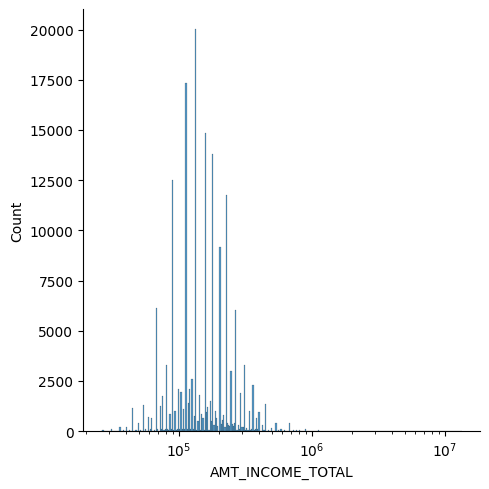

In [ ]:
# The distribution of AMT_INCOME_TOTAL（Logarithmic transformation）
sns.displot(data=train, x="AMT_INCOME_TOTAL", log_scale=10)
plt.show()

We displayed the graph successfully by using logarithmic transformation.
The income is supposed to be a continuous value, but it looks like a discrete value. Let's have a look at the type of `AMT_INCOME_TOTAL` values.

In [ ]:
# Check the type of AMT_INCOME_TOTAL values
len(train["AMT_INCOME_TOTAL"].unique())

1641

In [ ]:
# Check the type of AMT_CREDIT values
len(train["AMT_CREDIT"].unique())

4796

In [ ]:
# Check the type of AMT_ANNUITY values
len(train["AMT_ANNUITY"].unique())

12241

In [ ]:
# Check the type of AMT_GOODS_PRICE values
len(train["AMT_GOODS_PRICE"].unique())

904

There are 171202 data in train, but `AMT_INCOME_TOTAL` consists of only 1641 different values. Let's check the top 10 values specifically.

In [ ]:
# Top 10 values of AMT_INCOME_TOTAL
train["AMT_INCOME_TOTAL"].value_counts().head(10)

,count
AMT_INCOME_TOTAL,
135000.0,19969
112500.0,17320
157500.0,14772
180000.0,13791
90000.0,12481
225000.0,11573
202500.0,9128
67500.0,6130
270000.0,6006


It appears that `AMT_INCOME_TOTAL` is not an exact annual income, but rather data compiled from a rounded number.

**Findings**:<br>
* Should the outlier in the data be addressed?

DAYS_EMPLOYED


#### OWN_CAR_AGE column

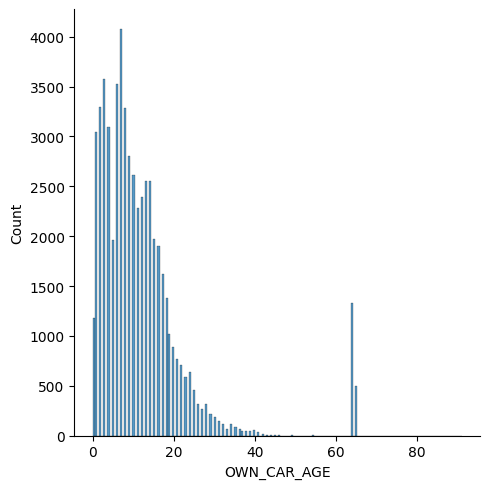

In [ ]:
# The distribution of OWN_CAR_AGE
sns.displot(data=train, x="OWN_CAR_AGE")
plt.show()

`OWN_CAR_AGE` can be inferred to be in years from the scale of values. In addition, the distribution is natural from 0 to 40, but there is an unnatural distribution around 60 to 70. It is hard to imagine that the number of years a car has been purchased increases suddenly like this, so they are considered to be outliers.

**Findings**:<br>
* Treat numbers above 60 as outliers

Up to this point, we have visualized and analyzed each feature. I believe that you have realized that visualization requires some ingenuity and that visualization can deepen your understanding of data. I am sure that the visualization and analysis of the 25 features not covered here will lead to improved forecasting accuracy.

### **[Next Steps]**
> + Check for missing values for the features you have added in Section 2.2.
> + Visualize the features you have added. Is the feature categorical or continuous? What type of graph is most effective to understand it?
> + What do you notice about the features? What kind of preprocessing is needed?

In [ ]:
# Check missing values of train data
train.isnull().sum()

,0
NAME_CONTRACT_TYPE,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_1,118928
EXT_SOURCE_2,369
EXT_SOURCE_3,54586
DAYS_BIRTH,0
DAYS_EMPLOYED,0
ORGANIZATION_TYPE,0
OWN_CAR_AGE,112992
AMT_CREDIT,0


## 4.Preprocessing and Feature Creation
Here, we will conduct the preprocessing and create new features based on what we have learned in the preceding visualization and analysis.

In [83]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

def preprocess_home_credit_data(df: pd.DataFrame):
    """
    Applies custom domain-specific and statistical transformations to all continuous
    and discrete numerical features based on visual distribution profiles.
    """
    df = df.copy()

    # ---------------------------------------------------------
    # 1. ANOMALY CLEANING & FIXES
    # ---------------------------------------------------------
    # Handle the classic 365243 anomaly in DAYS_EMPLOYED
    if 'DAYS_EMPLOYED' in df.columns:
        df['DAYS_EMPLOYED_ANOM'] = (df['DAYS_EMPLOYED'] == 365243).astype(int)
        df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)

    # ---------------------------------------------------------
    # 2. MISSING VALUE INDICATORS & IMPUTATION
    # ---------------------------------------------------------
    ext_cols = ['EXT_SOURCES_MEAN', 'EXT_SOURCES_PROD', 'EXT_SOURCES_STD']
    for col in ext_cols:
        if col in df.columns:
            # Create explicit missing indicator column (crucial for GBDTs)
            df[f'{col}_IS_NA'] = df[col].isnull().astype(int)

    # Median Impute target EXT_SOURCES columns
    imputer = SimpleImputer(strategy='median')
    existing_ext = [c for c in ext_cols if c in df.columns]
    if existing_ext:
        df[existing_ext] = imputer.fit_transform(df[existing_ext])

    # ---------------------------------------------------------
    # 3. HEAVILY SKEWED FEATURES -> LOG1P TRANSFORM
    # ---------------------------------------------------------
    # Columns exhibiting heavy right-skew across histograms
    skewed_cols = [
        'AMT_INCOME_TOTAL', 'CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO',
        'CREDIT_GOODS_RATIO', 'GOODS_INCOME_RATIO', 'INCOME_PER_PERSON',
        'CREDIT_PER_PERSON', 'INCOME_TO_AGE_RATIO', 'INCOME_AFTER_ANNUITY',
        'CREDIT_TO_FAMILY_INCOME_CAPACITY', 'AMT_CREDIT', 'AMT_ANNUITY',
        'AMT_GOODS_PRICE'
    ]

    for col in skewed_cols:
        if col in df.columns:
            # Shift minimum to 0 before log1p if negative values exist
            min_val = df[col].min()
            if min_val < 0:
                df[col] = np.log1p(df[col] - min_val)
            else:
                df[col] = np.log1p(df[col])

    # ---------------------------------------------------------
    # 4. OUTLIER CLIPPING (1st to 99th Percentile)
    # ---------------------------------------------------------
    # Prevents extreme spikes/leverage points from disrupting Logistic Regression
    unbounded_cols = [
        'AMT_INCOME_TOTAL', 'INCOME_PER_PERSON', 'CREDIT_PER_PERSON',
        'INCOME_TO_AGE_RATIO', 'CREDIT_TO_FAMILY_INCOME_CAPACITY',
        'GOODS_FINANCING_GAP_RATIO'
    ]

    for col in unbounded_cols:
        if col in df.columns:
            lower_bound = df[col].quantile(0.01)
            upper_bound = df[col].quantile(0.99)
            df[col] = np.clip(df[col], lower_bound, upper_bound)

#     # ---------------------------------------------------------
#     # 5. MODEL-SPECIFIC PIPELINE SPLITS
#     # ---------------------------------------------------------
#     # For Tree-Based Models (XGBoost, CatBoost, RandomForest):
#     # Preserves native feature splits without requiring normalization.
#     df_tree = df.copy()

#     # For Linear Models (Logistic Regression):
#     # Scale all numerical continuous features to zero mean and unit variance.
#     df_linear = df.copy()
#     num_cols = df_linear.select_dtypes(include=[np.number]).columns

#     scaler = StandardScaler()
#     df_linear[num_cols] = scaler.fit_transform(df_linear[num_cols].fillna(df_linear[num_cols].median()))

#     return df_tree, df_linear

# # Example Usage:
# # X_train_tree, X_train_linear = preprocess_home_credit_data(train_df)

In [84]:
# Automatically find all categorical/object columns (excluding target or ID if needed)
categorical_cols = train.select_dtypes(include=['object', 'category']).columns

# Create a shared mapping dictionary and apply it consistently to both train and test
for col in categorical_cols:
    # Combine unique categories from both train and test to ensure identical mapping
    combined = pd.concat([train[col], test[col]], axis=0).astype(str)
    categories = sorted(combined.unique())

    # Create mapping dictionary {category_name: integer_code}
    cat_to_code = {cat: idx for idx, cat in enumerate(categories)}

    # Apply mapping consistently (unknowns in test map to -1 or a default code)
    train[col] = train[col].astype(str).map(cat_to_code).fillna(-1).astype(int)
    test[col] = test[col].astype(str).map(cat_to_code).fillna(-1).astype(int)

# Handle any remaining missing values in numerical columns
train.fillna(0, inplace=True)
test.fillna(0, inplace=True)

**NAME_FAMILY_STATUS**

In [85]:
# Safe Label Encoding for NAME_FAMILY_STATUS
for col in ["NAME_FAMILY_STATUS"]:
    combined = pd.concat([train[col], test[col]], axis=0).astype(str)
    categories = sorted(combined.unique())
    cat_to_code = {cat: idx for idx, cat in enumerate(categories)}

    train[col] = train[col].astype(str).map(cat_to_code).fillna(-1).astype(int)
    test[col] = test[col].astype(str).map(cat_to_code).fillna(-1).astype(int)

**OCCUPATION_TYPE**

In [86]:
# Fill missing text values with 'Unknown' and encode
col = "OCCUPATION_TYPE"
train[col] = train[col].fillna("Unknown").astype(str)
test[col] = test[col].fillna("Unknown").astype(str)

combined = pd.concat([train[col], test[col]], axis=0)
categories = sorted(combined.unique())
cat_to_code = {cat: idx for idx, cat in enumerate(categories)}

train[col] = train[col].map(cat_to_code).astype(int)
test[col] = test[col].map(cat_to_code).astype(int)

**FLAG_EMP_PHONE** & **FLAG_WORK_PHONE**

In [87]:
# Ensure binary flags have no missing values
flag_cols = ["FLAG_EMP_PHONE", "FLAG_WORK_PHONE"]
for col in flag_cols:
    train[col] = train[col].fillna(0).astype(int)
    test[col] = test[col].fillna(0).astype(int)

"DAYS_EMPLOYED"

In [ ]:
# Replace the 365243 anomaly with NaN (missing value)
train.loc[train["DAYS_EMPLOYED"] == 365243, "DAYS_EMPLOYED"] = np.nan
test.loc[test["DAYS_EMPLOYED"] == 365243, "DAYS_EMPLOYED"] = np.nan

# Create a binary column: 1 if they were unemployed/missing, 0 if employed
train["DAYS_EMPLOYED_isnan"] = train["DAYS_EMPLOYED"].isnull().astype(int)
test["DAYS_EMPLOYED_isnan"] = test["DAYS_EMPLOYED"].isnull().astype(int)

# Then fill the missing days with the median or mean of actual employed people
emp_mean = train["DAYS_EMPLOYED"].mean()
train["DAYS_EMPLOYED"].fillna(emp_mean, inplace=True)
test["DAYS_EMPLOYED"].fillna(emp_mean, inplace=True)

"NAME_EDUCATION_TYPE"

In [88]:
# Automatically find and encode any remaining object/text columns in train and test
categorical_cols = train.select_dtypes(include=['object', 'category']).columns

for col in categorical_cols:
    train[col] = train[col].astype('category').cat.codes
    test[col] = test[col].astype('category').cat.codes

# Also fill any remaining missing values with 0 so StandardScaler doesn't crash on NaNs
train.fillna(0, inplace=True)
test.fillna(0, inplace=True)

"NAME_INCOME_TYPE","NAME_HOUSING_TYPE","CODE_GENDER", "FLAG_OWN_REALTY"

In [89]:
# 1. Encode categorical text features (using label encoding / category codes)
cat_cols = ["NAME_INCOME_TYPE", "NAME_HOUSING_TYPE","CODE_GENDER", "FLAG_OWN_REALTY"]
for col in cat_cols:
    if col in train.columns:
        train[col] = train[col].astype('category').cat.codes
        test[col] = test[col].astype('category').cat.codes



"CNT_CHILDREN", "REGION_POPULATION_RELATIVE", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH"

In [ ]:
# 2. Handle missing values for numerical features
num_cols = ["CNT_CHILDREN", "REGION_POPULATION_RELATIVE", "DAYS_REGISTRATION", "DAYS_ID_PUBLISH","DAYS_LAST_PHONE_CHANGE", "CNT_FAM_MEMBERS", "REGION_RATING_CLIENT"]
for col in num_cols:
    if col in train.columns:
        train[col].fillna(train[col].median(), inplace=True)
        test[col].fillna(test[col].median(), inplace=True)

AMT_REQ_CREDIT_BUREAU_MON, AMT_REQ_CREDIT_BUREAU_QRT, and AMT_REQ_CREDIT_BUREAU_YEAR

In [90]:
# Fill missing bureau requests with 0 or -1
for col in ["AMT_REQ_CREDIT_BUREAU_MON", "AMT_REQ_CREDIT_BUREAU_QRT", "AMT_REQ_CREDIT_BUREAU_YEAR"]:
    train[col].fillna(0, inplace=True)
    test[col].fillna(0, inplace=True)

### NAME_CONTRACT_TYPE column
Convert `NAME_CONTRACT_TYPE` to a numeric type. In this case, “Cash loans” is converted to 0 and “Revolving loans” to 1. This method of simply replacing an integer is called **Label Encoding**.

In [91]:
# Numerization of NAME_CONTRACT_TYPE（Label Encoding）
train["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)
test["NAME_CONTRACT_TYPE"].replace({'Cash loans': 0, 'Revolving loans': 1}, inplace=True)

### ORGANIZATION_TYPE column
Convert `ORGANIZATION_TYPE` to a numeric type. This time, we will convert the variable to numeric in terms of the number of data in the variable. For example, if the number of data in “Police” is 1279 and the number of data in “Bank” is 1385, convert “Police” to 1279 and “Bank” to 1385. This method of replacing the number of data with the number of data is called **Count Encoding**.

In [92]:
# Numerization of ORGANIZATION_TYPE (Count Encoding）
organization_ce = train["ORGANIZATION_TYPE"].value_counts()
train["ORGANIZATION_TYPE"] = train["ORGANIZATION_TYPE"].map(organization_ce)
test["ORGANIZATION_TYPE"] = test["ORGANIZATION_TYPE"].map(organization_ce)

train.head(100)

,AMT_INCOME_TOTAL,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_BIRTH,DAYS_EMPLOYED,OWN_CAR_AGE,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_LAST_PHONE_CHANGE,CNT_FAM_MEMBERS,CNT_CHILDREN,REGION_POPULATION_RELATIVE,DAYS_REGISTRATION,DAYS_ID_PUBLISH,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_GOODS_RATIO,GOODS_INCOME_RATIO,ANNUITY_CREDIT_RATIO,INCOME_PER_PERSON,CREDIT_PER_PERSON,CREDIT_MINUS_GOODS,AGE_YEARS,INCOME_TO_AGE_RATIO,EMPLOYED_TO_AGE_RATIO,EXT_SOURCES_MEAN,EXT_SOURCES_PROD,EXT_SOURCES_STD,INCOME_AFTER_ANNUITY,ESTIMATED_REPAYMENT_DURATION,CREDIT_TO_FAMILY_INCOME_CAPACITY,GOODS_FINANCING_GAP_RATIO,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,CODE_GENDER,REGION_RATING_CLIENT,NAME_INCOME_TYPE,NAME_HOUSING_TYPE,NAME_FAMILY_STATUS,OCCUPATION_TYPE,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_MOBIL,TARGET
0,112500,0.000000,0.372591,0.000000,-9233,-878,0,755190,36328.5,675000,-292,2,0,0.010032,-333,-522,6.712800,0.322920,1.118800,5.999947,0.048105,56250,377595,80190,25,4450.408860,0.095094,0.372591,0.00000,0.000000,-323442,20.787239,13.425361,0.118800,0,4991,5,23,11,24,0,1,7,1,1,12,1,1,1,0
1,225000,0.000000,0.449567,0.553165,-20148,365243,0,585000,16893.0,585000,-617,2,0,0.008019,-4469,-3436,2.600000,0.075080,1.000000,2.599988,0.028877,112500,292500,0,55,4078.878797,-18.128003,0.501366,0.00000,0.073255,22284,34.627678,5.199954,0.000000,0,30898,0,0,0,1,0,1,3,1,1,4,0,0,1,0
2,54000,0.000000,0.569503,0.000000,-18496,-523,0,334152,18256.5,270000,-542,2,0,0.004960,-3640,-2050,6.188000,0.338083,1.237600,4.999907,0.054635,27000,167076,64152,50,1066.365701,0.028276,0.569503,0.00000,0.000000,-165078,18.302177,12.375542,0.237599,0,1185,5,23,11,24,0,1,4,1,1,12,1,1,1,0
3,67500,0.000000,0.105235,0.767523,-24177,365243,0,152820,8901.0,135000,0,1,0,0.005002,-4950,-3951,2.264000,0.131867,1.132000,1.999970,0.058245,67500,152820,17820,66,1019.745006,-15.107044,0.436379,0.00000,0.468309,-39312,17.166929,2.263966,0.131999,0,30898,0,0,0,0,0,2,3,1,5,4,0,0,1,0
4,157500,0.342344,0.202490,0.669057,-10685,-697,0,271066,21546.0,234000,-1243,2,0,0.006296,-5101,-3226,1.721057,0.136800,1.158404,1.485705,0.079486,78750,135533,37066,29,5383.890969,0.065232,0.404630,0.04638,0.239439,-101052,12.580243,3.442071,0.158403,0,37943,0,0,0,18,1,2,1,5,1,13,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,162000,0.000000,0.739825,0.852828,-24047,365243,15,247275,17338.5,225000,-598,1,0,0.018634,-7404,-4561,1.526389,0.107028,1.099000,1.388880,0.070118,162000,247275,22275,65,2460.618788,-15.188714,0.796327,0.00000,0.079906,-46062,14.260792,1.526379,0.099000,0,30898,0,0,0,18,0,1,3,1,5,4,0,0,1,0
96,135000,0.850819,0.360583,0.000000,-21293,365243,11,824823,24246.0,688500,-1136,2,0,0.010147,-3226,-3259,6.109800,0.179600,1.198000,5.099962,0.029395,67500,412411,136323,58,2315.725825,-17.153196,0.605701,0.00000,0.346650,-155952,34.017528,12.219419,0.198000,0,30898,0,0,0,0,0,1,3,1,1,4,0,0,1,0
97,157500,0.000000,0.672693,0.780144,-21827,365243,0,1609272,47182.5,1260000,-352,2,0,0.072508,-893,-4293,10.217600,0.299571,1.277200,7.999949,0.029319,78750,804636,349272,59,2635.583223,-16.733541,0.726418,0.00000,0.075979,-408690,34.106669,20.434941,0.277200,0,30898,0,0,0,1,0,0,3,1,1,4,0,0,1,0
98,112500,0.000000,0.321716,0.551381,-10225,-41,0,675000,34596.0,675000,0,2,0,0.018209,-4635,-2887,6.000000,0.307520,1.000000,5.999947,0.051253,56250,337500,0,27,4018.643032,0.004010,0.436549,0.00000,0.162398,-302652,19.510362,11.999787,0.000000,0,3004,0,0,0,12,1,2,7,5,0,18,1,0,1,0


### EXT_SOURCE_2 column
Fill missing values in `EXT_SOURCE_2`. There are various methods for completing missing values, but in this case, since the number of missing values is small, we simply use the average value to complete the missing values.

**IMPORANT**:
When you fill the missing values in the test data, you need to **fill with the average of the train data**.

"EXT_SOURCE_1", "EXT_SOURCE_3"

In [93]:
# Fill missing values with -1 so trees can separate missing data cleanly
for col in ["EXT_SOURCE_1", "EXT_SOURCE_3"]:
    train[col].fillna(-1, inplace=True)
    test[col].fillna(-1, inplace=True)

In [94]:
# Complete missing values of EXT_SOURCE_2 with the average
train["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True)
test["EXT_SOURCE_2"].fillna(train["EXT_SOURCE_2"].mean(), inplace=True) # Use average of train data to fill test data

train.isnull().sum()

,0
AMT_INCOME_TOTAL,0
EXT_SOURCE_1,0
EXT_SOURCE_2,0
EXT_SOURCE_3,0
DAYS_BIRTH,0
DAYS_EMPLOYED,0
OWN_CAR_AGE,0
AMT_CREDIT,0
AMT_ANNUITY,0
AMT_GOODS_PRICE,0


### OWN_CAR_AGE column
First, we will replace the unnatural outliers that are over 60 as `np.nan` (missing values).

In [95]:
# Treat values above 60 (outliers) in OWN_CAR_AGE as missing values
train.loc[train["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan
test.loc[test["OWN_CAR_AGE"] >= 60, "OWN_CAR_AGE"] = np.nan

Next, we consider the handling of missing values. The original `OWN_CAR_AGE` had 112992 missing values out of 171202 data. With such a large number of missing values, it is difficult and impractical to properly fill the missing values with some value. Therefore, we will group `OWN_CAR_AGE` by decade (e.g. Group 1: 0-9 years, Group 2: 10-19 years, etc.), then apply **One Hot Encoding**.

In [96]:
# Divide OWN_CAR_AGE into groups
train["OWN_CAR_AGE"] = train["OWN_CAR_AGE"] // 10
test["OWN_CAR_AGE"] = test["OWN_CAR_AGE"] // 10

train["OWN_CAR_AGE"].unique()

array([ 0.,  2.,  1., nan,  3.,  4.,  5.])

In [97]:
# Apply One Hot Encoding to OWN_CAR_AGE
train_car_age_ohe = pd.get_dummies(train["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")
test_car_age_ohe = pd.get_dummies(test["OWN_CAR_AGE"]).add_prefix("OWN_CAR_AGE_")

# Add the one hot encoded columns to train/test
train = pd.concat([train, train_car_age_ohe], axis=1)
test = pd.concat([test, test_car_age_ohe], axis=1)

# Remove original OWN_CAR_AGE
train.drop('OWN_CAR_AGE', axis=1, inplace=True)
test.drop('OWN_CAR_AGE', axis=1, inplace=True)

train.head(5)

,AMT_INCOME_TOTAL,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_BIRTH,DAYS_EMPLOYED,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_LAST_PHONE_CHANGE,CNT_FAM_MEMBERS,CNT_CHILDREN,REGION_POPULATION_RELATIVE,DAYS_REGISTRATION,DAYS_ID_PUBLISH,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_GOODS_RATIO,GOODS_INCOME_RATIO,ANNUITY_CREDIT_RATIO,INCOME_PER_PERSON,CREDIT_PER_PERSON,CREDIT_MINUS_GOODS,AGE_YEARS,INCOME_TO_AGE_RATIO,EMPLOYED_TO_AGE_RATIO,EXT_SOURCES_MEAN,EXT_SOURCES_PROD,EXT_SOURCES_STD,INCOME_AFTER_ANNUITY,ESTIMATED_REPAYMENT_DURATION,CREDIT_TO_FAMILY_INCOME_CAPACITY,GOODS_FINANCING_GAP_RATIO,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,CODE_GENDER,REGION_RATING_CLIENT,NAME_INCOME_TYPE,NAME_HOUSING_TYPE,NAME_FAMILY_STATUS,OCCUPATION_TYPE,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_MOBIL,TARGET,OWN_CAR_AGE_0.0,OWN_CAR_AGE_1.0,OWN_CAR_AGE_2.0,OWN_CAR_AGE_3.0,OWN_CAR_AGE_4.0,OWN_CAR_AGE_5.0
0,112500,0.000000,0.372591,0.000000,-9233,-878,755190,36328.5,675000,-292,2,0,0.010032,-333,-522,6.712800,0.322920,1.118800,5.999947,0.048105,56250,377595,80190,25,4450.408860,0.095094,0.372591,0.00000,0.000000,-323442,20.787239,13.425361,0.118800,0,4991,5,23,11,24,0,1,7,1,1,12,1,1,1,0,True,False,False,False,False,False
1,225000,0.000000,0.449567,0.553165,-20148,365243,585000,16893.0,585000,-617,2,0,0.008019,-4469,-3436,2.600000,0.075080,1.000000,2.599988,0.028877,112500,292500,0,55,4078.878797,-18.128003,0.501366,0.00000,0.073255,22284,34.627678,5.199954,0.000000,0,30898,0,0,0,1,0,1,3,1,1,4,0,0,1,0,True,False,False,False,False,False
2,54000,0.000000,0.569503,0.000000,-18496,-523,334152,18256.5,270000,-542,2,0,0.004960,-3640,-2050,6.188000,0.338083,1.237600,4.999907,0.054635,27000,167076,64152,50,1066.365701,0.028276,0.569503,0.00000,0.000000,-165078,18.302177,12.375542,0.237599,0,1185,5,23,11,24,0,1,4,1,1,12,1,1,1,0,True,False,False,False,False,False
3,67500,0.000000,0.105235,0.767523,-24177,365243,152820,8901.0,135000,0,1,0,0.005002,-4950,-3951,2.264000,0.131867,1.132000,1.999970,0.058245,67500,152820,17820,66,1019.745006,-15.107044,0.436379,0.00000,0.468309,-39312,17.166929,2.263966,0.131999,0,30898,0,0,0,0,0,2,3,1,5,4,0,0,1,0,True,False,False,False,False,False
4,157500,0.342344,0.202490,0.669057,-10685,-697,271066,21546.0,234000,-1243,2,0,0.006296,-5101,-3226,1.721057,0.136800,1.158404,1.485705,0.079486,78750,135533,37066,29,5383.890969,0.065232,0.404630,0.04638,0.239439,-101052,12.580243,3.442071,0.158403,0,37943,0,0,0,18,1,2,1,5,1,13,1,1,1,1,True,False,False,False,False,False


### **[Next Steps]**
> + Apply preprocessing to the features you added. Is it correctly preprocessed?
> + Explore other preprocessing methods to apply to the features.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1).

In [98]:
train.head(100)

,AMT_INCOME_TOTAL,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_BIRTH,DAYS_EMPLOYED,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,DAYS_LAST_PHONE_CHANGE,CNT_FAM_MEMBERS,CNT_CHILDREN,REGION_POPULATION_RELATIVE,DAYS_REGISTRATION,DAYS_ID_PUBLISH,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_GOODS_RATIO,GOODS_INCOME_RATIO,ANNUITY_CREDIT_RATIO,INCOME_PER_PERSON,CREDIT_PER_PERSON,CREDIT_MINUS_GOODS,AGE_YEARS,INCOME_TO_AGE_RATIO,EMPLOYED_TO_AGE_RATIO,EXT_SOURCES_MEAN,EXT_SOURCES_PROD,EXT_SOURCES_STD,INCOME_AFTER_ANNUITY,ESTIMATED_REPAYMENT_DURATION,CREDIT_TO_FAMILY_INCOME_CAPACITY,GOODS_FINANCING_GAP_RATIO,NAME_CONTRACT_TYPE,ORGANIZATION_TYPE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,CODE_GENDER,REGION_RATING_CLIENT,NAME_INCOME_TYPE,NAME_HOUSING_TYPE,NAME_FAMILY_STATUS,OCCUPATION_TYPE,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_MOBIL,TARGET,OWN_CAR_AGE_0.0,OWN_CAR_AGE_1.0,OWN_CAR_AGE_2.0,OWN_CAR_AGE_3.0,OWN_CAR_AGE_4.0,OWN_CAR_AGE_5.0
0,112500,0.000000,0.372591,0.000000,-9233,-878,755190,36328.5,675000,-292,2,0,0.010032,-333,-522,6.712800,0.322920,1.118800,5.999947,0.048105,56250,377595,80190,25,4450.408860,0.095094,0.372591,0.00000,0.000000,-323442,20.787239,13.425361,0.118800,0,4991,5,23,11,24,0,1,7,1,1,12,1,1,1,0,True,False,False,False,False,False
1,225000,0.000000,0.449567,0.553165,-20148,365243,585000,16893.0,585000,-617,2,0,0.008019,-4469,-3436,2.600000,0.075080,1.000000,2.599988,0.028877,112500,292500,0,55,4078.878797,-18.128003,0.501366,0.00000,0.073255,22284,34.627678,5.199954,0.000000,0,30898,0,0,0,1,0,1,3,1,1,4,0,0,1,0,True,False,False,False,False,False
2,54000,0.000000,0.569503,0.000000,-18496,-523,334152,18256.5,270000,-542,2,0,0.004960,-3640,-2050,6.188000,0.338083,1.237600,4.999907,0.054635,27000,167076,64152,50,1066.365701,0.028276,0.569503,0.00000,0.000000,-165078,18.302177,12.375542,0.237599,0,1185,5,23,11,24,0,1,4,1,1,12,1,1,1,0,True,False,False,False,False,False
3,67500,0.000000,0.105235,0.767523,-24177,365243,152820,8901.0,135000,0,1,0,0.005002,-4950,-3951,2.264000,0.131867,1.132000,1.999970,0.058245,67500,152820,17820,66,1019.745006,-15.107044,0.436379,0.00000,0.468309,-39312,17.166929,2.263966,0.131999,0,30898,0,0,0,0,0,2,3,1,5,4,0,0,1,0,True,False,False,False,False,False
4,157500,0.342344,0.202490,0.669057,-10685,-697,271066,21546.0,234000,-1243,2,0,0.006296,-5101,-3226,1.721057,0.136800,1.158404,1.485705,0.079486,78750,135533,37066,29,5383.890969,0.065232,0.404630,0.04638,0.239439,-101052,12.580243,3.442071,0.158403,0,37943,0,0,0,18,1,2,1,5,1,13,1,1,1,1,True,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,162000,0.000000,0.739825,0.852828,-24047,365243,247275,17338.5,225000,-598,1,0,0.018634,-7404,-4561,1.526389,0.107028,1.099000,1.388880,0.070118,162000,247275,22275,65,2460.618788,-15.188714,0.796327,0.00000,0.079906,-46062,14.260792,1.526379,0.099000,0,30898,0,0,0,18,0,1,3,1,5,4,0,0,1,0,False,True,False,False,False,False
96,135000,0.850819,0.360583,0.000000,-21293,365243,824823,24246.0,688500,-1136,2,0,0.010147,-3226,-3259,6.109800,0.179600,1.198000,5.099962,0.029395,67500,412411,136323,58,2315.725825,-17.153196,0.605701,0.00000,0.346650,-155952,34.017528,12.219419,0.198000,0,30898,0,0,0,0,0,1,3,1,1,4,0,0,1,0,False,True,False,False,False,False
97,157500,0.000000,0.672693,0.780144,-21827,365243,1609272,47182.5,1260000,-352,2,0,0.072508,-893,-4293,10.217600,0.299571,1.277200,7.999949,0.029319,78750,804636,349272,59,2635.583223,-16.733541,0.726418,0.00000,0.075979,-408690,34.106669,20.434941,0.277200,0,30898,0,0,0,1,0,0,3,1,1,4,0,0,1,0,True,False,False,False,False,False
98,112500,0.000000,0.321716,0.551381,-10225,-41,675000,34596.0,675000,0,2,0,0.018209,-4635,-2887,6.000000,0.307520,1.000000,5.999947,0.051253,56250,337500,0,27,4018.643032,0.004010,0.436549,

## 5.Building the Machine Learning Model
Now, we are ready to start building the machine learning model.

### 5.1 Import Additional Libraries
First, we import the necessary libraries for training and evaluation.

- `train_test_split`: Split data into training and evaluation data.
- `StandardScaler`: Standardize the data.
- `roc_auc_score`: Calculate ROC-AUC, the evaluation metric for this competition.

In [99]:
# Importing libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

### 5.2 Preparing the Data
Split the data into explanatory and target variables. The target variable for this dataset is `TARGET` column and the rest are explanatory variables.

In [102]:
# Split the data into explanatory and target variables
X = train.drop("TARGET", axis=1).values
y = train["TARGET"].values
X_test = test.values

Standardize the data. Standardization is the operation of transforming the values so that the mean is 0 and the variance is 1. Some models, such as logistic regression and neural networks, do not learn well without scaling the values in this way.

In [101]:
# Standardization
sc = StandardScaler()
sc.fit(X)
X_std = sc.transform(X)
X_test_std = sc.transform(X_test)

### 5.3 Training the Model
We first split the training data into training data and validation data. This method of keeping a portion of the training data for evaluation and not using it for training is called the **holdout method**. This is one method to approximate the model's predictive ability on unknown data (**generalization** performance).

Here, we will use 70% of the data as training data and 30% as validation data

In [103]:
# Split the original data into the training data and the validation data
X_train, X_valid, y_train, y_valid = train_test_split(X_std, y, test_size=0.3, stratify=y, random_state=0)

Now, let's create models with logistic regression and random forest.

In [104]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(random_state=0)
lr.fit(X_train, y_train)

lr_train_pred = lr.predict_proba(X_train)[:, 1]
lr_valid_pred = lr.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, lr_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, lr_valid_pred)}")

Train Score: 0.7347671123131495
Valid Score: 0.7338226275417249


In [105]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=0, max_depth=10)
rf.fit(X_train, y_train)

rf_train_pred = rf.predict_proba(X_train)[:, 1]
rf_valid_pred = rf.predict_proba(X_valid)[:, 1]
print(f"Train Score: {roc_auc_score(y_train, rf_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, rf_valid_pred)}")

Train Score: 0.8497073896611085
Valid Score: 0.7384712520176534


In [106]:
#LightGBM
import lightgbm as lgb

# Initialize and train LightGBM
lgb_model = lgb.LGBMClassifier(
    n_estimators=674,        # More trees
    learning_rate=0.024707196127270147,      # Slower learning rate for better generalization
    num_leaves=27,           # Control tree complexity
    max_depth=7,             # Prevent deep overfitting
    subsample=0.729251883217942,           # Row sampling per tree
    colsample_bytree=0.6751379519118348,    # Column sampling per split
    random_state=42,
    verbose=-1,
    reg_alpha=1.9947295707800559,
    reg_lambda=0.4899764683881752,
    n_jobs=-1
)
lgb_model.fit(X_train, y_train)

# Predict probabilities
lgb_train_pred = lgb_model.predict_proba(X_train)[:, 1]
lgb_valid_pred = lgb_model.predict_proba(X_valid)[:, 1]

print(f"Train Score: {roc_auc_score(y_train, lgb_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, lgb_valid_pred)}")

Train Score: 0.8357921709971997
Valid Score: 0.7549524327522502


In [ ]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]


In [ ]:
import optuna
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

def objective_lgb(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 300, 1000),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.05, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 64),
        'max_depth': trial.suggest_int('max_depth', 4, 8),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-3, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-3, 10.0, log=True),
        'random_state': 42,
        'verbose': -1,
        'n_jobs': -1
    }

    model = lgb.LGBMClassifier(**params)
    model.fit(X_train, y_train)
    preds = model.predict_proba(X_valid)[:, 1]
    return roc_auc_score(y_valid, preds)

# Run optimization study
optuna.logging.set_verbosity(optuna.logging.WARNING)
study_lgb = optuna.create_study(direction='maximize')
study_lgb.optimize(objective_lgb, n_trials=20)

print("Best LightGBM Validation AUC:", study_lgb.best_value)
print("Best LightGBM Parameters:", study_lgb.best_params)

Best LightGBM Validation AUC: 0.7556212794067066
Best LightGBM Parameters: {'n_estimators': 742, 'learning_rate': 0.02359563771824966, 'num_leaves': 24, 'max_depth': 6, 'subsample': 0.6195619927895972, 'colsample_bytree': 0.6562569936231819, 'reg_alpha': 0.16795235258406035, 'reg_lambda': 0.22666195397033675}


In [107]:
!pip install catboost

In [108]:
# CatBoost Model
from catboost import CatBoostClassifier

cb_model = CatBoostClassifier(
    iterations=1140,
    learning_rate=0.0633531402177257,
    depth=5,
    eval_metric='AUC',
    random_seed=42,
    verbose=0,
    l2_leaf_reg=8.210712600359598
)
cb_model.fit(X_train, y_train, eval_set=(X_valid, y_valid), early_stopping_rounds=50)

# Predict probabilities
cb_train_pred = cb_model.predict_proba(X_train)[:, 1]
cb_valid_pred = cb_model.predict_proba(X_valid)[:, 1]

print(f"Train Score: {roc_auc_score(y_train, cb_train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, cb_valid_pred)}")

Train Score: 0.7936800734020322
Valid Score: 0.7551295893266523


In [ ]:
from catboost import CatBoostClassifier

def objective_cb(trial):
    params = {
        'iterations': trial.suggest_int('iterations', 500, 1200),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.08, log=True),
        'depth': trial.suggest_int('depth', 4, 8),
        'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1e-3, 10.0, log=True),
        'random_seed': 42,
        'eval_metric': 'AUC',
        'verbose': 0
    }

    model = CatBoostClassifier(**params)
    model.fit(X_train, y_train, eval_set=(X_valid, y_valid), early_stopping_rounds=50)
    preds = model.predict_proba(X_valid)[:, 1]
    return roc_auc_score(y_valid, preds)

# Run optimization study
study_cb = optuna.create_study(direction='maximize')
study_cb.optimize(objective_cb, n_trials=20)

print("Best CatBoost Validation AUC:", study_cb.best_value)
print("Best CatBoost Parameters:", study_cb.best_params)

[W 2026-10-27 16:04:25,664] Trial 0 failed with parameters: {'iterations': 765, 'learning_rate': 0.02521119941805562, 'depth': 7, 'l2_leaf_reg': 0.005907662209309837} because of the following error: KeyboardInterrupt('').
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/optuna/study/_optimize.py", line 206, in _run_trial
    value_or_values = func(trial)
  File "/tmp/ipykernel_1040/3579856934.py", line 15, in objective_cb
    model.fit(X_train, y_train, eval_set=(X_valid, y_valid), early_stopping_rounds=50)
    ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/catboost/core.py", line 5547, in fit
    self._fit(X, y, cat_features, text_features, embedding_features, None, graph, sample_weight, None, None, None, None, baseline, use_best_model,
    ~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

KeyboardInterrupt: 

In [ ]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

# Set up 5-fold cross-validation
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lgb_oof = np.zeros(len(train))
cb_oof = np.zeros(len(train))

# Example loop for LightGBM with K-Fold
for fold, (train_idx, valid_idx) in enumerate(skf.split(X, y)):
    X_tr, y_tr = X[train_idx], y[train_idx]
    X_va, y_va = X[valid_idx], y[valid_idx]

    # Train LightGBM
    lgb_model.fit(X_tr, y_tr)
    lgb_oof[valid_idx] = lgb_model.predict_proba(X_va)[:, 1]

print(f"OOF CV Score: {roc_auc_score(y, lgb_oof):.5f}")

We find that random forest results with higher validation score.

### 5.4 (Optional) Ensemble Learning
Now that we have created two models, we can try combining these two models for better predictive ability (**ensemble learning**). There are various methods for ensemble learning, but here we will simply take the average of the two models.

In [109]:
train_pred = (lr_train_pred + rf_train_pred) / 2
valid_pred = (lr_valid_pred + rf_valid_pred) / 2

print(f"Train Score: {roc_auc_score(y_train, train_pred)}")
print(f"Valid Score: {roc_auc_score(y_valid, valid_pred)}")

Train Score: 0.8048346237749461
Valid Score: 0.7400774770745989


In [ ]:
# Blend predictions
ensemble_valid_pred = (0.8 * lgb_valid_pred) + (0.2 * rf_valid_pred)

# Check the new ensemble validation score
print(f"Ensemble Valid Score: {roc_auc_score(y_valid, ensemble_valid_pred)}")

In [110]:
# Blend predictions from LightGBM and CatBoost
ensemble_valid_pred = (0.6 * lgb_valid_pred) + (0.4 * cb_valid_pred)

# Check the new ensemble validation score
print(f"Ensemble Valid Score: {roc_auc_score(y_valid, ensemble_valid_pred)}")

Ensemble Valid Score: 0.756535506230569


We find that in this case, ensemble leaning does not contribute to improved score. So, **we will use the random forest model as the final model to make predictions on the test data**.

### **[Next Steps]**
> + Is holdout method the best method to evaluate your model?
> + Is the model's hyperparameters optimized? What hyperparameters needs tuning?
> + Explore other models to use to make predictions.
> + Explore other ensembling methods to further improve the model's performance.
> + If you have errors, try reloading the dataset by going back to [Section 2.1](#scrollTo=2TTHzi1c3a5E&line=5&uniqifier=1).

## 6.Creating Prediction Results
Finally, let's make a prediction for the test data, and prepare a CSV file to submit.

### 6.1 Predicting on the test data
We found in Sections 5.3 and 5.4 that the best model was random forest model. Therefore, we will use this model to make the final prediction.

If you made any changes and found a better model, you will need to change the code below accordingly.

```python
# If logistic regression model was better
pred = lr.predict_proba(X_test_std)[:, 1]
```

In [ ]:
# Generate test probabilities for both models
lgb_test_pred = lgb_model.predict_proba(X_test_std)[:, 1]
rf_test_pred = rf.predict_proba(X_test_std)[:, 1]

# Blend test predictions
pred = (0.8 * lgb_test_pred) + (0.2 * rf_test_pred)


In [111]:
# Generate test probabilities for both LightGBM and CatBoost models
lgb_test_pred = lgb_model.predict_proba(X_test_std)[:, 1]
cb_test_pred = cb_model.predict_proba(X_test_std)[:, 1]

# Blend the test predictions using your optimized weights (60% LightGBM + 40% CatBoost)
pred = (0.6 * lgb_test_pred) + (0.4 * cb_test_pred)

### 6.2 Saving the prediction as CSV file [DO NOT CHANGE]
**WARNING**: DO **NOT** CHANGE THE CODES BELOW!!!

In [112]:
# Put the prediction into the format of submission
sample_sub['TARGET'] = pred
sample_sub

,SK_ID_CURR,TARGET
0,171202,0.038214
1,171203,0.219655
2,171204,0.121077
3,171205,0.107891
4,171206,0.202713
...,...,...
61495,232697,0.226732
61496,232698,0.034062
61497,232699,0.057288
61498,232700,0.182307


In [113]:
# Create the "output" directory if it doesn't exist
output_dir = current_dir / "output"
os.makedirs(output_dir, exist_ok=True)

# Specify the new output file path
output_file = output_dir / "submission.csv"

# Save the CSV file to the "output" directory
sample_sub.to_csv(output_file, index=False)

That's all for the tutorial of Home Credit Default Risk competition! Submit your CSV file to Omnicampus to see the result.

Only 5 out of 30 features are covered in this notebook, so there are a lot of room for improvement. Check out **[Next Steps]** in each section to see what you can do to improve your score.

### 6.3 Saving this notebook as a ZIP file [REQUIREMENT IF AIMING FOR HONORS/OUTSTANDING STUDENTS]
This section compresses the notebook file (`tutorial.ipynb`) into a ZIP file and saves it to your working directory.
Make sure to save the notebook (Ctrl+S or Cmd+S) before running this cell to include the latest changes.

If you are aiming to become **Honors or Outstanding Student**, you need to submit the ZIP file as well on Omnicampus.

In [ ]:
import zipfile

# Define the file names
notebook_filename = "tutorial.ipynb" # Enter the name of this notebook
zip_filename = "tutorial.zip"

# Define the full paths using current_dir
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename

# Check if the notebook file exists and create the ZIP file
if notebook_path.exists():
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        # Add the notebook to the ZIP file (arcname avoids including the full folder structure)
        zipf.write(notebook_path, arcname=notebook_filename)
    print(f"Successfully created: {zip_output_path}")
else:
    print(f"Error: Could not find '{notebook_filename}' in {current_dir}.")
    print("Please check if the notebook name and the current directory are correct.")